# Series en $G$ (AUTOG): señales CPMG y Hahn y contrastes, sin ajustes, medidos y con el piso restado

Gráficos cualitativos de las series en $G$ de una sesión: señales CPMG y Hahn contra $G$ para todos los tiempos $T$ y el contraste
$\Delta M = M_{CPMG} - M_{Hahn}$, **uniendo los puntos, sin ajustar ningún modelo**, una vez con la señal medida y otra con el piso de ruido de la
magnitud restado. El objetivo es ver el comportamiento de los contrastes en cada dirección para todos los tiempos, y en particular el de las fibras
frente al agua libre, donde el ajuste libre de $D_0$ no describe las fibras (`nogse_fits_trapezoidal_lobes*.ipynb` tienen los ajustes del agua).

Cada serie: 2 b0 y $G = 7, 14, \ldots, 70$ mT/m en las direcciones 1, 2, 3 del escáner ($x$, $y$, $z$); $S_0$ es la media de los b0 de la misma serie.
El contraste empareja CPMG y Hahn del mismo $T$, dirección y `b_step` (mismo $G$).

Salidas en `signal_analysis/results/autog_plots/sub-<SUB>/ses-<SESSION_ID>/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('No encuentro la raíz del proyecto.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from data_processing.result_signals import X_SWEEP_NAME

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
PROJECT_ROOT

PosixPath('/mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE')

## Configuración

`SESSION_ID` es la sesión de las series en $G$; el piso se mide en la misma sesión (`FLOOR_SESSION_ID = SESSION_ID`). Para PHANTOM-1/2:
`SESSION_ID = 'T0'` y `FLOOR_ROIS = ['water']`. `ROIS = None` usa todos los ROIs.

In [2]:
ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
SUB = 'PHANTOM-3'
SESSION_ID = '20261026NOGSEV2001FOV220M128SL01R1G070AUTOG'
FLOOR_SESSION_ID = SESSION_ID
ROIS = None  # p. ej. ['water1', 'fiber1']; None: todos
STAT = 'avg'

FLOOR_ROIS = ['water1', 'water2']  # free-water ROIs whose plateau gives F
FLOOR_FREE_MIN_SIGNAL = 0.2        # reference D0 only from points with S/S0 >= 0.2
PLATEAU_MAX_SIGNAL = 0.003         # plateau points: predicted attenuation below 0.3 %
FLOOR_F_OVERRIDE = None            # scanner units; set it to skip the plateau measurement

NUMERIC = ['td_ms', 'TN', 'N', 'x', 'G', 'g', 'ramp_time_ms', 'bvalue', 'b_step', 'value', 'S0', 'value_norm']
MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
master = pd.read_parquet(MASTER_PATH)
master_types = master['type'].astype(str).str.strip().str.upper()
is_sweep = master_types.eq('AUTOX') | master['protocol'].astype(str).str.contains(X_SWEEP_NAME)


def select_rows(session_id, kind, rois=None):
    # Weighted volumes (b_step > 0) of one session: kind 'autox' (x sweep) or 'autog' (CPMG and Hahn G series).
    subject = master['subj'].astype(str) == SUB
    sessions = sorted(master.loc[subject, 'session_id'].dropna().astype(str).unique())
    if session_id not in sessions:
        raise ValueError(f'SESSION_ID={session_id!r} is not in the master for {SUB}. Available: {sessions}')
    kind_mask = is_sweep if kind == 'autox' else (~is_sweep & master_types.isin(['CPMG', 'HAHN']))
    rows = master.loc[subject & (master['session_id'].astype(str) == session_id) &
                      (master['stat'].astype(str) == STAT) & kind_mask].copy()
    available_rois = sorted(rows['roi'].astype(str).unique())
    if rois is not None:
        missing = [roi for roi in rois if roi not in available_rois]
        if missing:
            raise ValueError(f'ROIs {missing} not in {SUB}, {session_id} ({kind}). Available: {available_rois}')
        rows = rows.loc[rows['roi'].astype(str).isin(rois)]
    if rows.empty:
        raise ValueError(f'No {kind} rows in {SUB}, {session_id}.')
    for column in NUMERIC:
        rows[column] = pd.to_numeric(rows[column], errors='coerce')
    rows['type'] = rows['type'].astype(str).str.strip().str.upper()
    rows['roi'] = rows['roi'].astype(str)
    rows['direction'] = rows['direction'].astype(str)
    return rows.loc[rows['b_step'] > 0].dropna(subset=['bvalue', 'value', 'S0', 'value_norm'])

OUTPUT_ROOT = REPO_ROOT / 'results' / 'autog_plots' / f'sub-{SUB}' / f'ses-{SESSION_ID}'
SIGNAL_DIR = OUTPUT_ROOT / 'signals'
CONTRAST_DIR = OUTPUT_ROOT / 'contrasts'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (SIGNAL_DIR, CONTRAST_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

data = select_rows(SESSION_ID, 'autog', ROIS)
data['G_plot'] = data['g'].round(1)
rois = sorted(data['roi'].unique())
times = sorted(data['td_ms'].unique())
directions = sorted(data['direction'].unique())
time_colors = dict(zip(times, plt.cm.viridis(np.linspace(0.05, 0.9, len(times)))))
print('Master:', MASTER_PATH)
print('Salida:', OUTPUT_ROOT)
display(data.groupby(['type', 'td_ms']).agg(n=('value', 'size'), x_ms=('x', 'first'), ramp_ms=('ramp_time_ms', 'first'),
                                            b_max=('bvalue', 'max')).reset_index())

Master: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/Data-BIDS/derivatives/signal_analysis/den_gr--manual/phantoms/nogse_experiments/master.long.parquet
Salida: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autog_plots/sub-PHANTOM-3/ses-20261026NOGSEV2001FOV220M128SL01R1G070AUTOG


,type,td_ms,n,x_ms,ramp_ms,b_max
0,CPMG,30.0,120,15.0,1.2,149.290871
1,CPMG,40.0,120,20.0,1.2,382.350821
2,CPMG,50.0,120,25.0,1.2,780.220707
3,CPMG,65.0,120,32.5,1.2,1781.927604
4,HAHN,30.0,120,5.0,1.2,391.245882
5,HAHN,40.0,120,5.0,1.2,1123.995530
6,HAHN,50.0,120,5.0,1.2,2449.359627
7,HAHN,65.0,120,5.0,1.2,5932.091622


## Piso de ruido de la magnitud

Igual que en los notebooks de ajuste con piso: $F$ (unidades del escáner) es la media de `value` en los puntos de meseta del agua libre de la sesión
`FLOOR_SESSION_ID` (`FLOOR_ROIS`): los puntos cuya atenuación predicha con un $D_0$ de referencia es menor que `PLATEAU_MAX_SIGNAL`; el $D_0$ de
referencia de cada ROI de agua sale de $e^{-bD_0}$ ajustado a sus puntos con $S/S_0 \ge$ `FLOOR_FREE_MIN_SIGNAL`. `FLOOR_F_OVERRIDE` impone $F$.
Señal con el piso restado:

$$a=\frac{\sqrt{\max(S^2-F^2,\,0)}}{\sqrt{S_0^2-F^2}}.$$

El piso cambia con la posición: en PHANTOM-3 la meseta de `fiber1` (≈ 12.5) está por debajo del $F$ del agua (≈ 16.8), así que en las fibras la
versión corregida puede estar sobrecorregida. `fiber2` tiene $S_0$ apenas por encima del piso: su señal es casi solo ruido.

In [3]:
def reference_d0(points):
    # D0 (mm^2/s) of exp(-b D0), M0 = 1, fitted to the points with S/S0 >= FLOOR_FREE_MIN_SIGNAL
    keep = points['value_norm'] >= FLOOR_FREE_MIN_SIGNAL
    b, s = points.loc[keep, 'bvalue'].to_numpy(float), points.loc[keep, 'value_norm'].to_numpy(float)
    result = minimize_scalar(lambda log_d0: np.mean((s - np.exp(-b * np.exp(log_d0)))**2),
                             bounds=np.log([1e-4, 1e-2]), method='bounded')
    return float(np.exp(result.x))


if FLOOR_F_OVERRIDE is not None:
    FLOOR_F = float(FLOOR_F_OVERRIDE)
    print(f'Floor F = {FLOOR_F:.2f} (FLOOR_F_OVERRIDE)')
else:
    floor_rows = select_rows(FLOOR_SESSION_ID, 'autog', FLOOR_ROIS)
    floor_d0 = {roi: reference_d0(rows) for roi, rows in floor_rows.groupby('roi')}
    floor_rows['a_predicted'] = np.exp(-floor_rows['bvalue'] * floor_rows['roi'].map(floor_d0))
    plateau = floor_rows.loc[floor_rows['a_predicted'] < PLATEAU_MAX_SIGNAL]
    if plateau.empty:
        raise ValueError('No plateau points: raise PLATEAU_MAX_SIGNAL or set FLOOR_F_OVERRIDE.')
    FLOOR_F = float(plateau['value'].mean())
    for roi, d0 in floor_d0.items():
        print(f'Reference D0 of {roi}: {d0 * 1e3:.3f} x 1e-3 mm²/s')
    print(f'Floor F = {FLOOR_F:.2f} (scanner units) from {len(plateau)} plateau points of {FLOOR_ROIS} in {FLOOR_SESSION_ID}')
    display(plateau.groupby('roi').agg(n=('value', 'size'), F=('value', 'mean'), s_mean=('value_norm', 'mean')).round(3))

data['value_norm_corr'] = (np.sqrt(np.clip(data['value']**2 - FLOOR_F**2, 0, None)) /
                           np.sqrt(np.clip(data['S0']**2 - FLOOR_F**2, 0, None)).replace(0, np.nan))
floor_table = data.groupby('roi').agg(S0=('S0', 'mean')).reset_index()
floor_table['c_floor'] = FLOOR_F / floor_table['S0']
floor_table['n_below_floor'] = data.groupby('roi')['value'].apply(lambda v: int((v < FLOOR_F).sum())).to_numpy()
floor_table.insert(0, 'F_scanner_units', FLOOR_F)
floor_table.to_csv(TABLE_DIR / 'noise_floor.csv', index=False)
display(floor_table.round(4))
for roi in floor_table.loc[floor_table['c_floor'] > 0.5, 'roi']:
    print(f'ATENCIÓN: {roi} tiene F/S0 > 0.5: su señal está casi entera sobre el piso.')

CORRECTIONS = {'medido': 'value_norm', 'piso restado': 'value_norm_corr'}
direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
direction_names = {'1': 'dirección 1 (x)', '2': 'dirección 2 (y)', '3': 'dirección 3 (z)'}
roi_styles = {'water1': ('tab:blue', 'o'), 'water2': ('tab:cyan', 's'), 'fiber1': ('tab:red', '^'), 'fiber2': ('tab:orange', 'v')}


def roi_style(roi):
    return roi_styles.get(roi, ('0.3', 'D'))


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=160, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')

Reference D0 of water1: 3.167 x 1e-3 mm²/s
Reference D0 of water2: 3.023 x 1e-3 mm²/s
Floor F = 16.75 (scanner units) from 42 plateau points of ['water1', 'water2'] in 20261026NOGSEV2001FOV220M128SL01R1G070AUTOG


,n,F,s_mean
roi,,,
water1,21,17.249,0.064
water2,21,16.256,0.060


,F_scanner_units,roi,S0,c_floor,n_below_floor
0,16.7524,fiber1,100.3917,0.1669,33
1,16.7524,fiber2,22.1795,0.7553,1
2,16.7524,water1,270.7771,0.0619,0
3,16.7524,water2,271.9243,0.0616,25


ATENCIÓN: fiber2 tiene F/S0 > 0.5: su señal está casi entera sobre el piso.


## Señales CPMG y Hahn: una figura por ROI y corrección

Filas: direcciones. Columnas: CPMG y Hahn. Una curva por tiempo $T$.

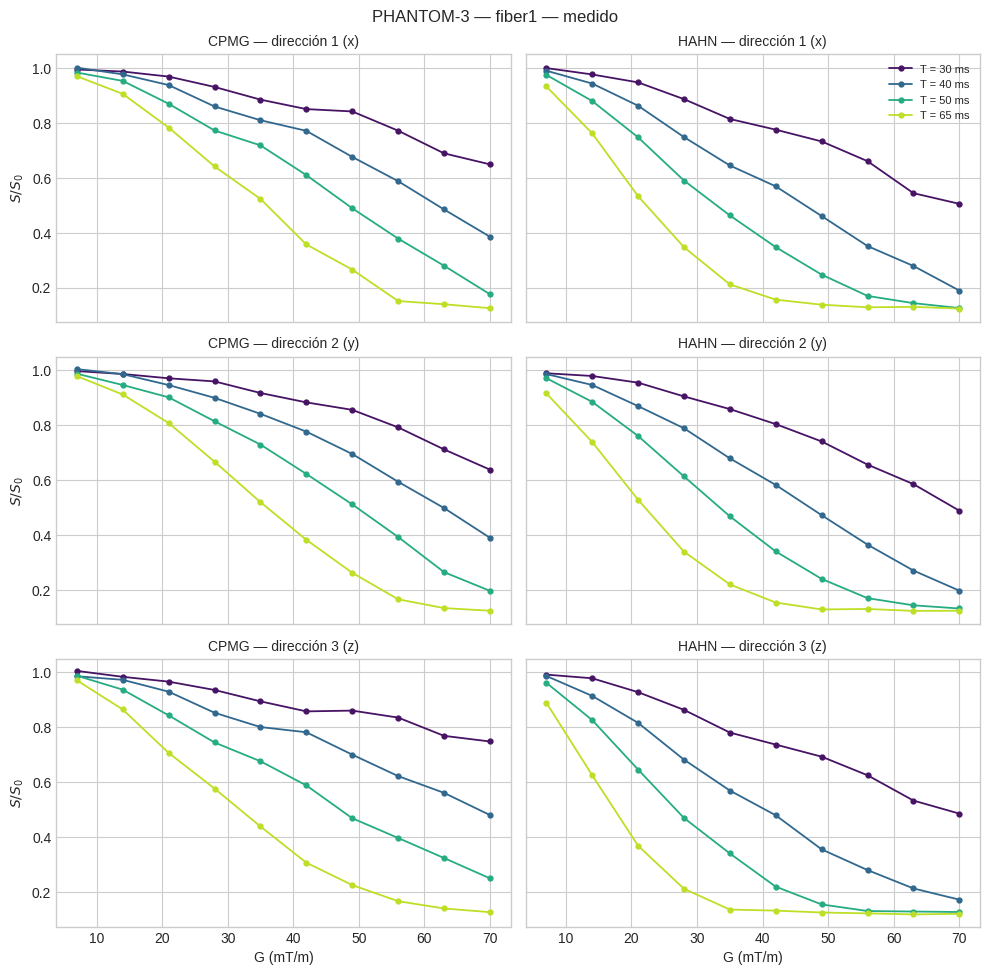

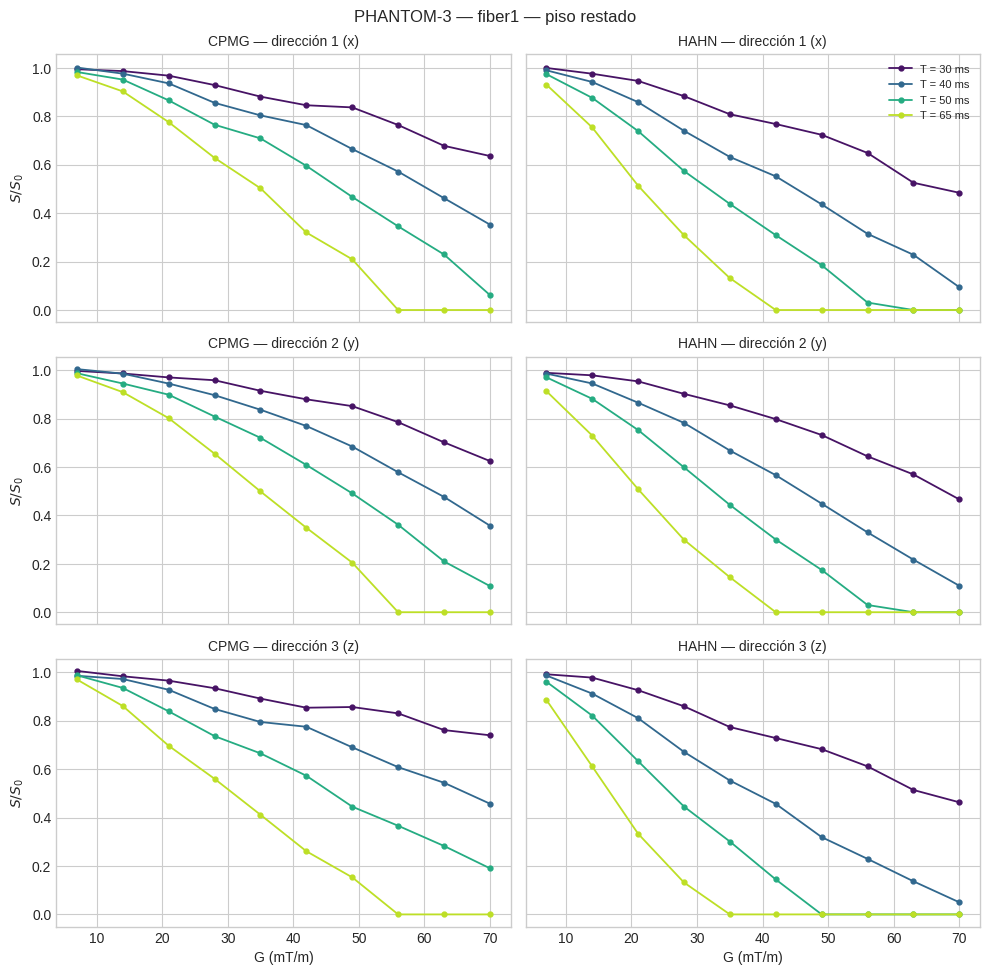

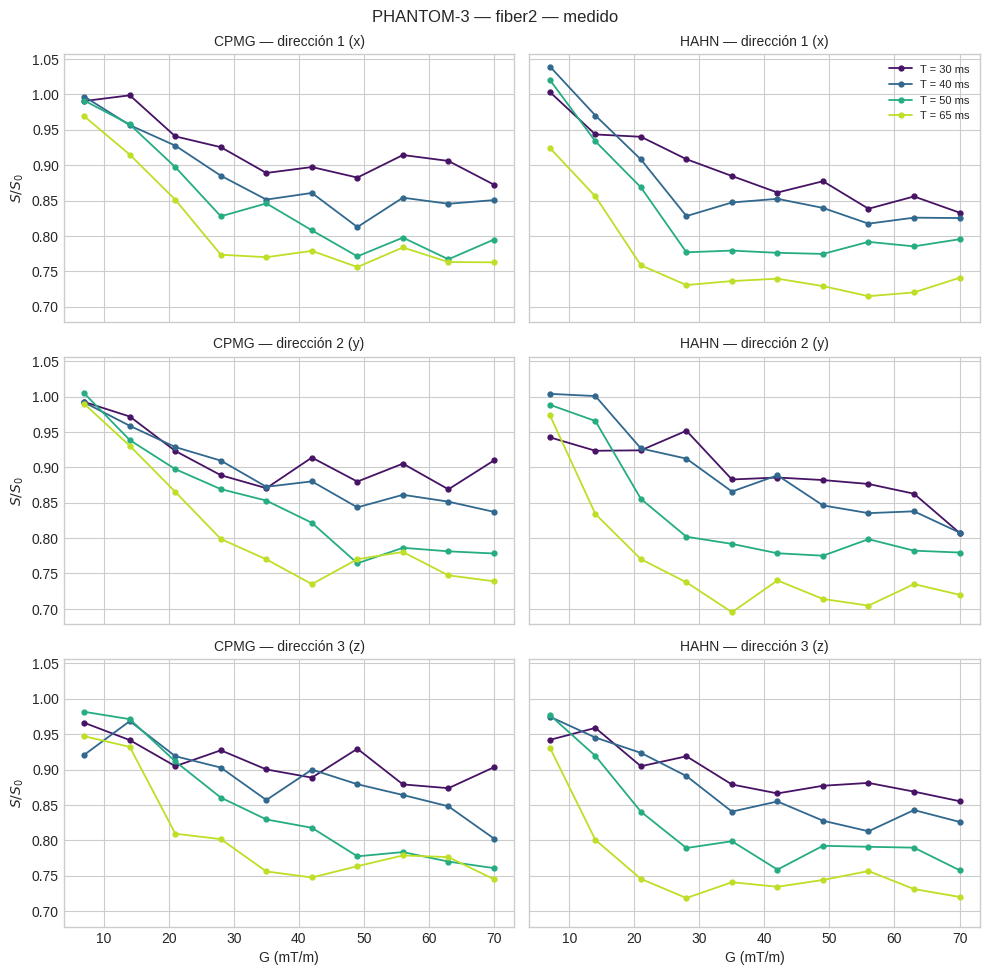

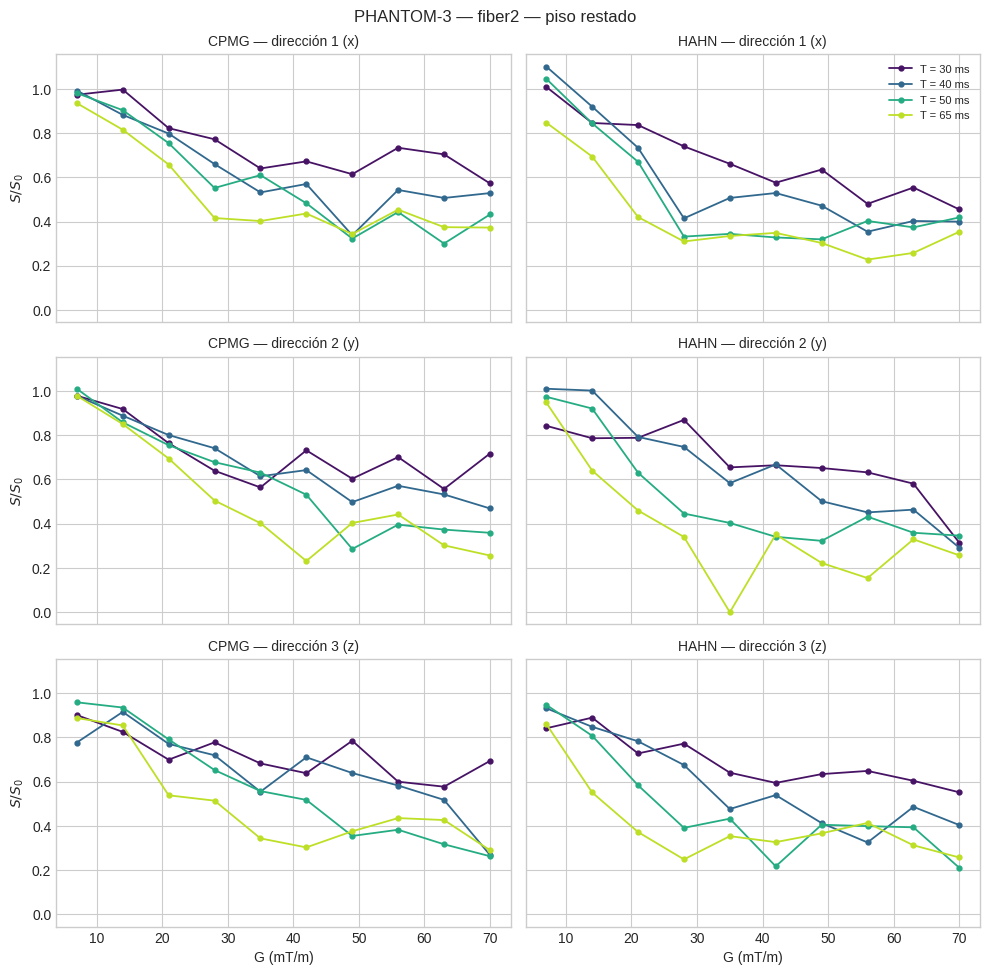

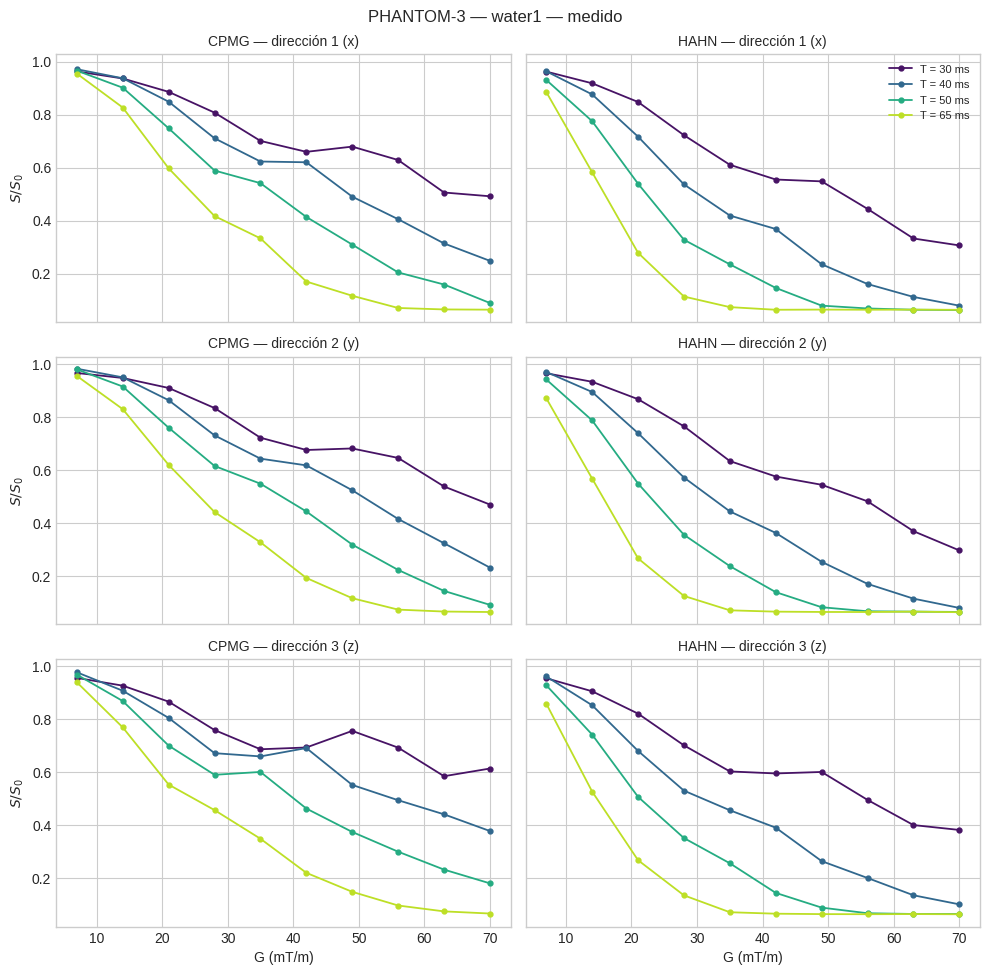

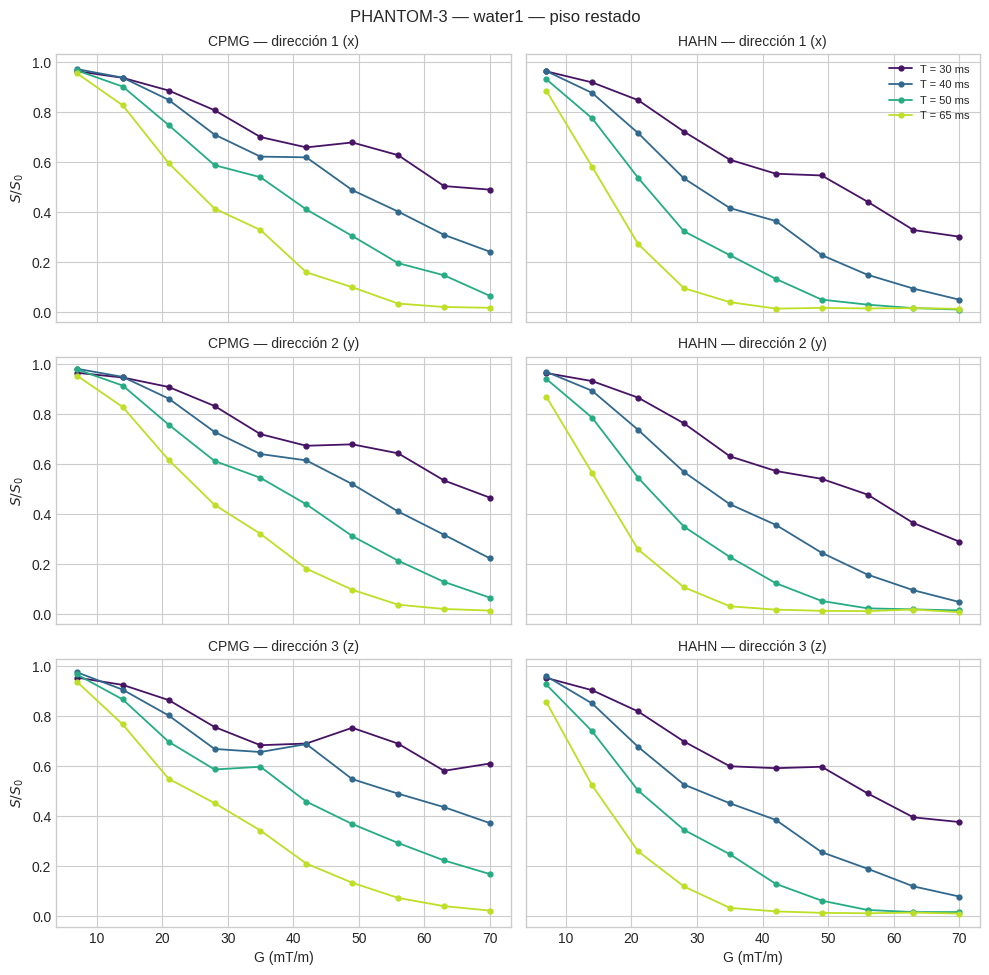

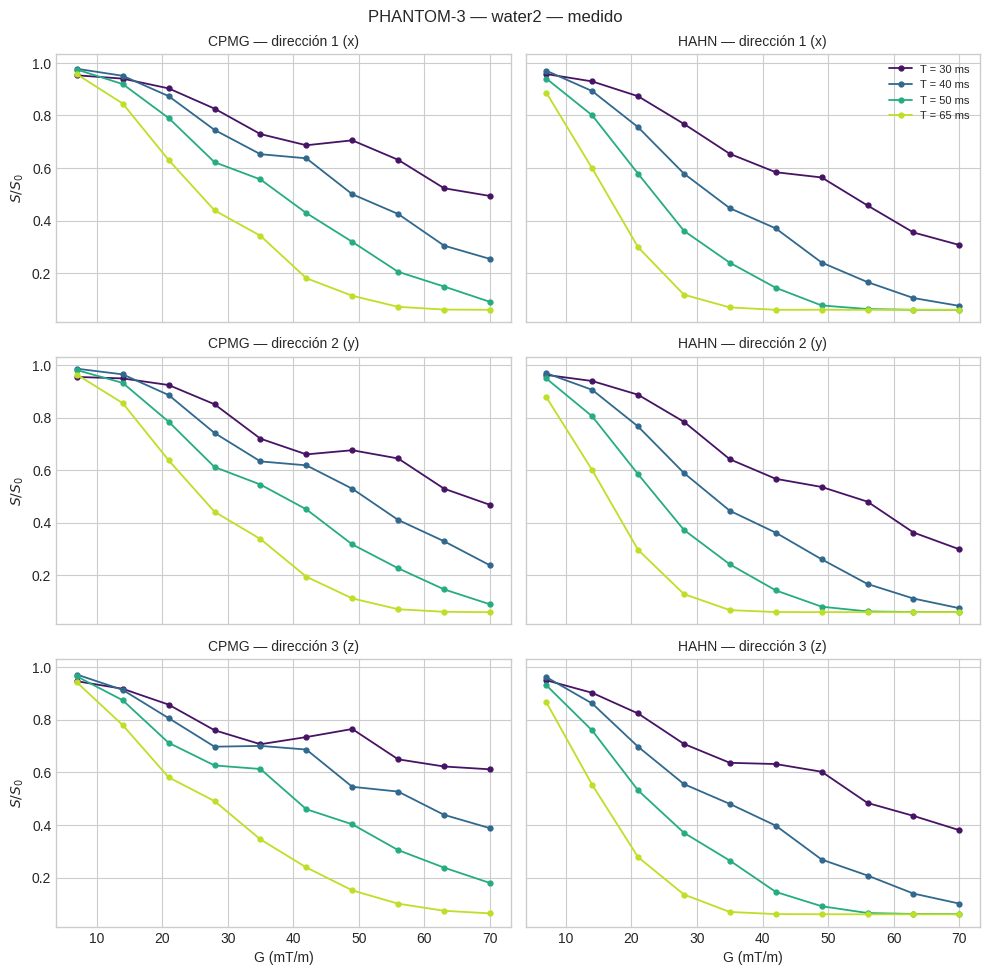

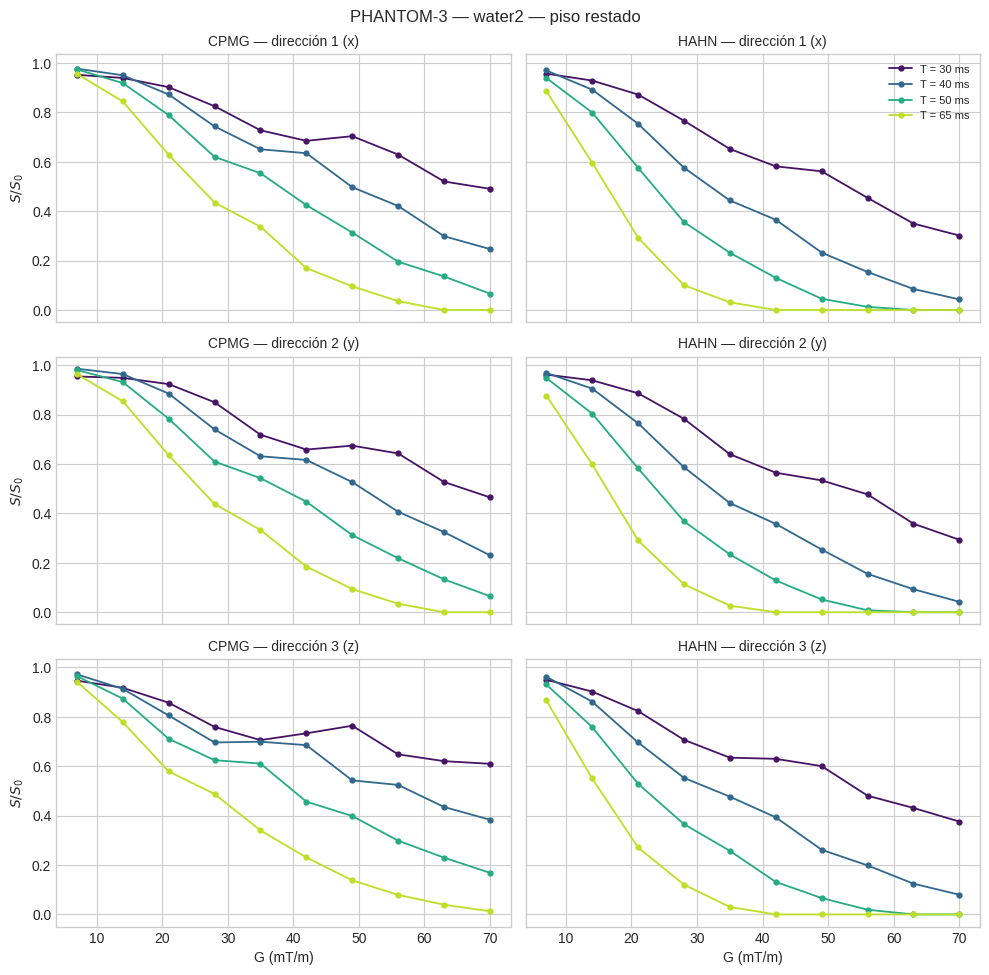

In [4]:
def plot_g_curve(ax, curve, column, color, marker, label):
    curve = curve.sort_values('b_step')
    ax.plot(curve['G_plot'], curve[column], '-', marker=marker, color=color, ms=3.5, lw=1.3, label=label)


for roi in rois:
    for correction, column in CORRECTIONS.items():
        fig, axes = plt.subplots(len(directions), 2, figsize=(10.0, 3.3 * len(directions)), sharex=True, sharey=True, squeeze=False)
        for row, direction in enumerate(directions):
            for col, sequence_type in enumerate(['CPMG', 'HAHN']):
                ax = axes[row, col]
                for td_ms in times:
                    curve = data.loc[data['roi'].eq(roi) & data['type'].eq(sequence_type) & data['td_ms'].eq(td_ms) &
                                     data['direction'].eq(direction)]
                    plot_g_curve(ax, curve, column, time_colors[td_ms], 'o', f'T = {td_ms:g} ms')
                ax.set_title(f'{sequence_type} — {direction_names.get(direction, direction)}', fontsize=10)
                if row == len(directions) - 1:
                    ax.set_xlabel('G (mT/m)')
                if col == 0:
                    ax.set_ylabel('$S/S_0$')
        axes[0, 1].legend(fontsize=8)
        fig.suptitle(f'{SUB} — {roi} — {correction}', fontsize=12)
        fig.tight_layout()
        save_figure(fig, SIGNAL_DIR, f'signal_{roi}_{column}')
        plt.show()

## Contrastes CPMG − Hahn por ROI

Filas: medido y con el piso restado. Columnas: direcciones. Una curva por $T$ (todos los tiempos).

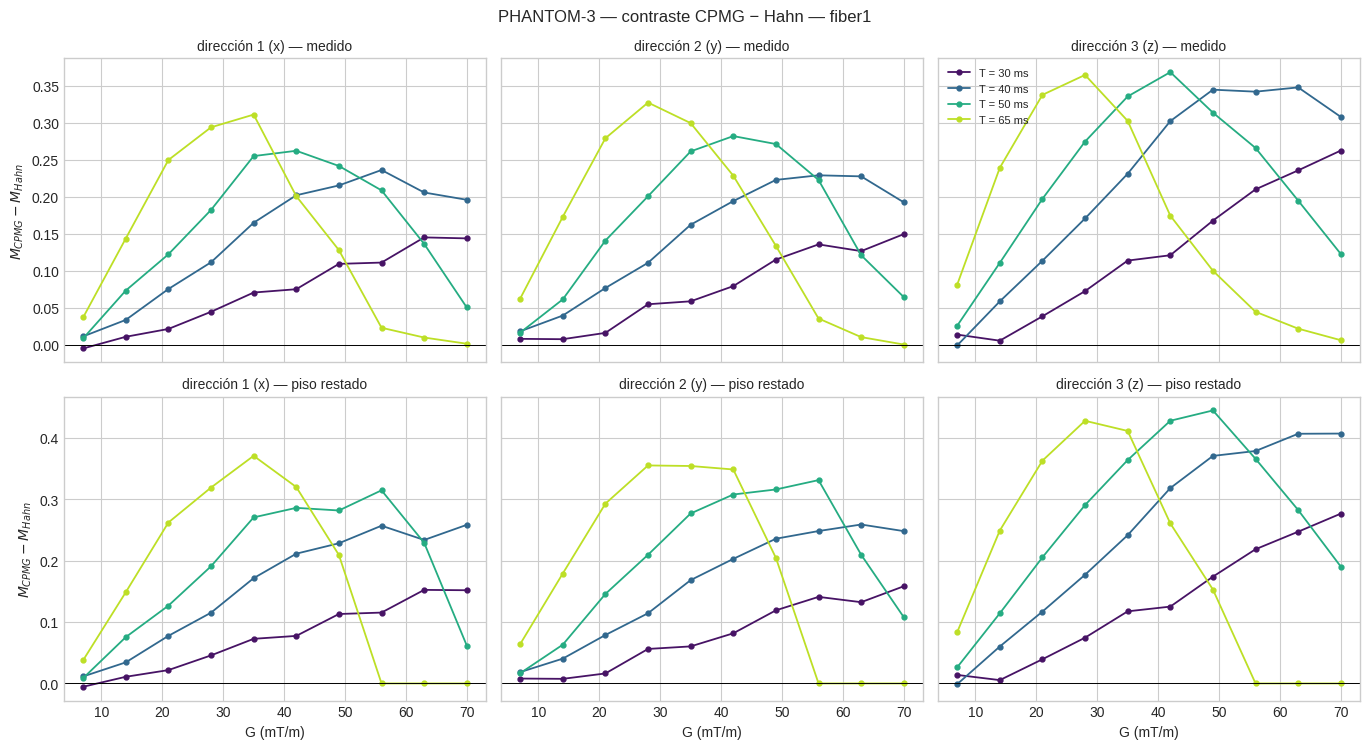

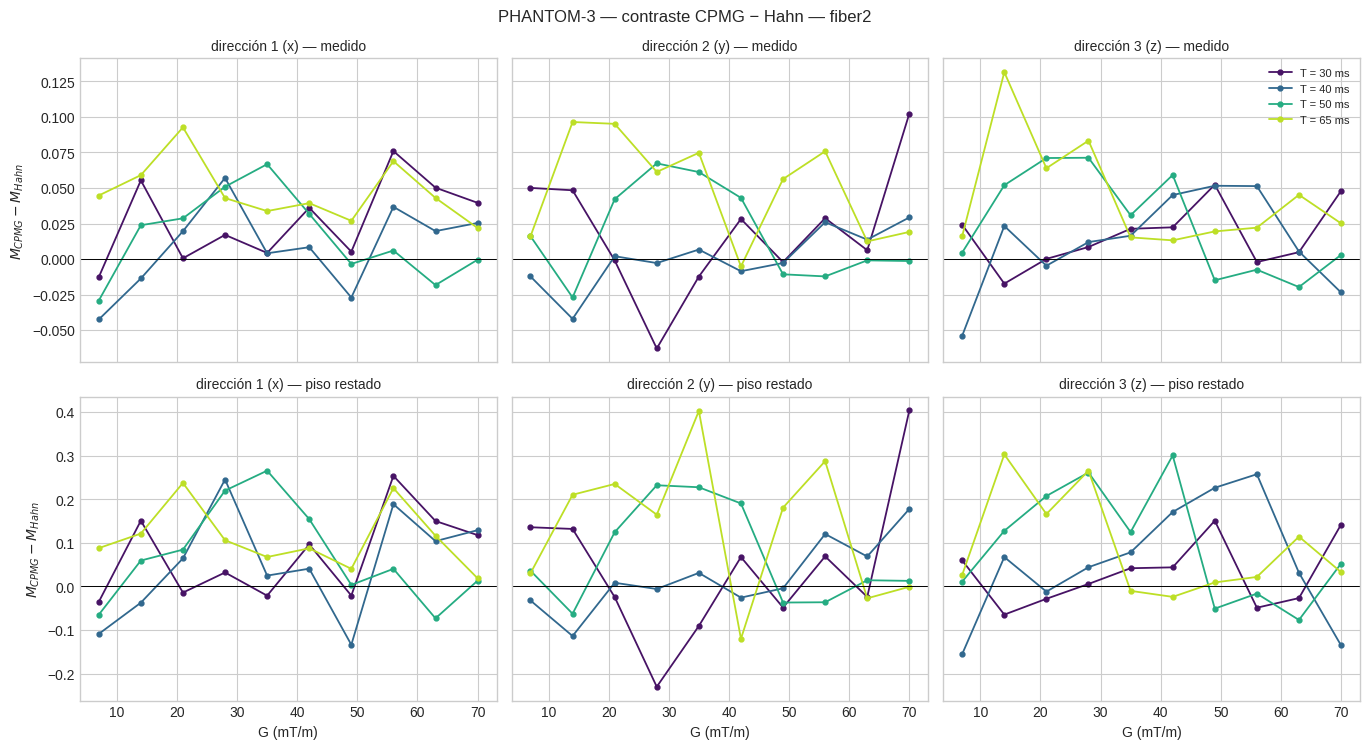

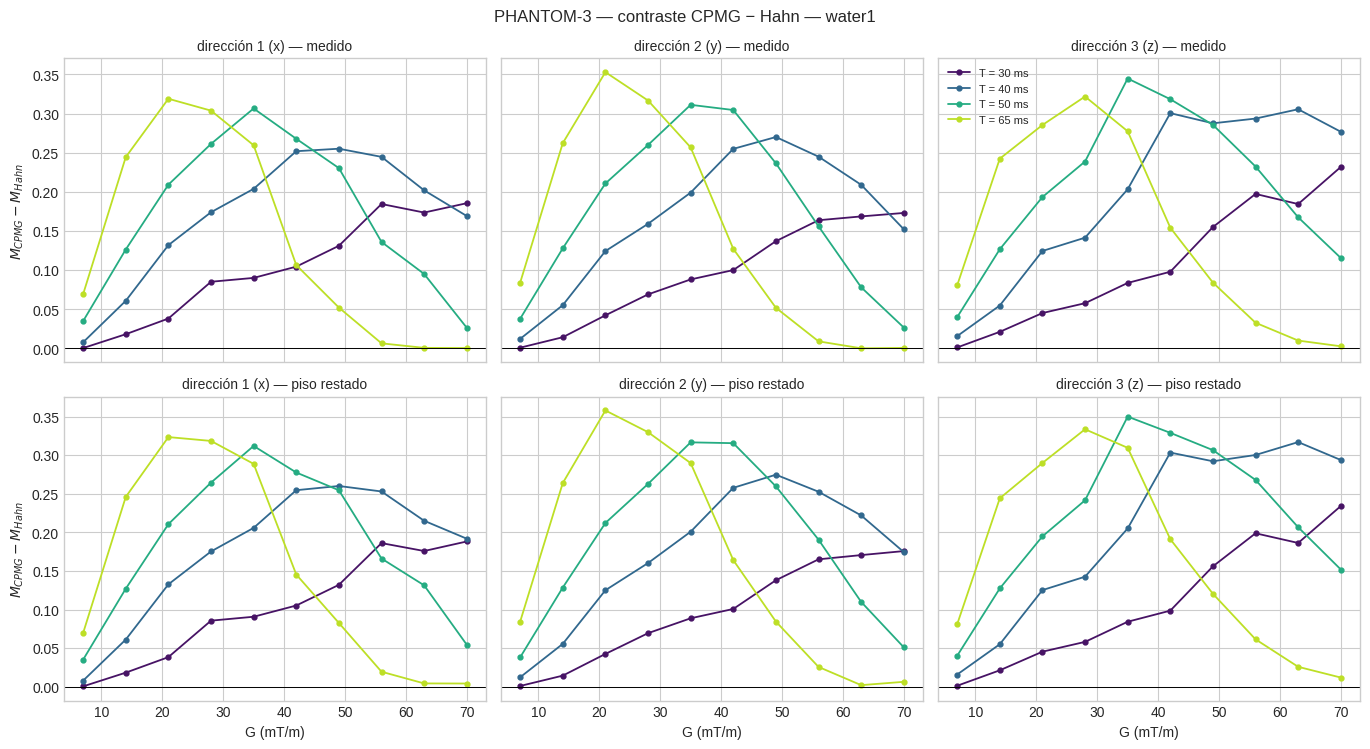

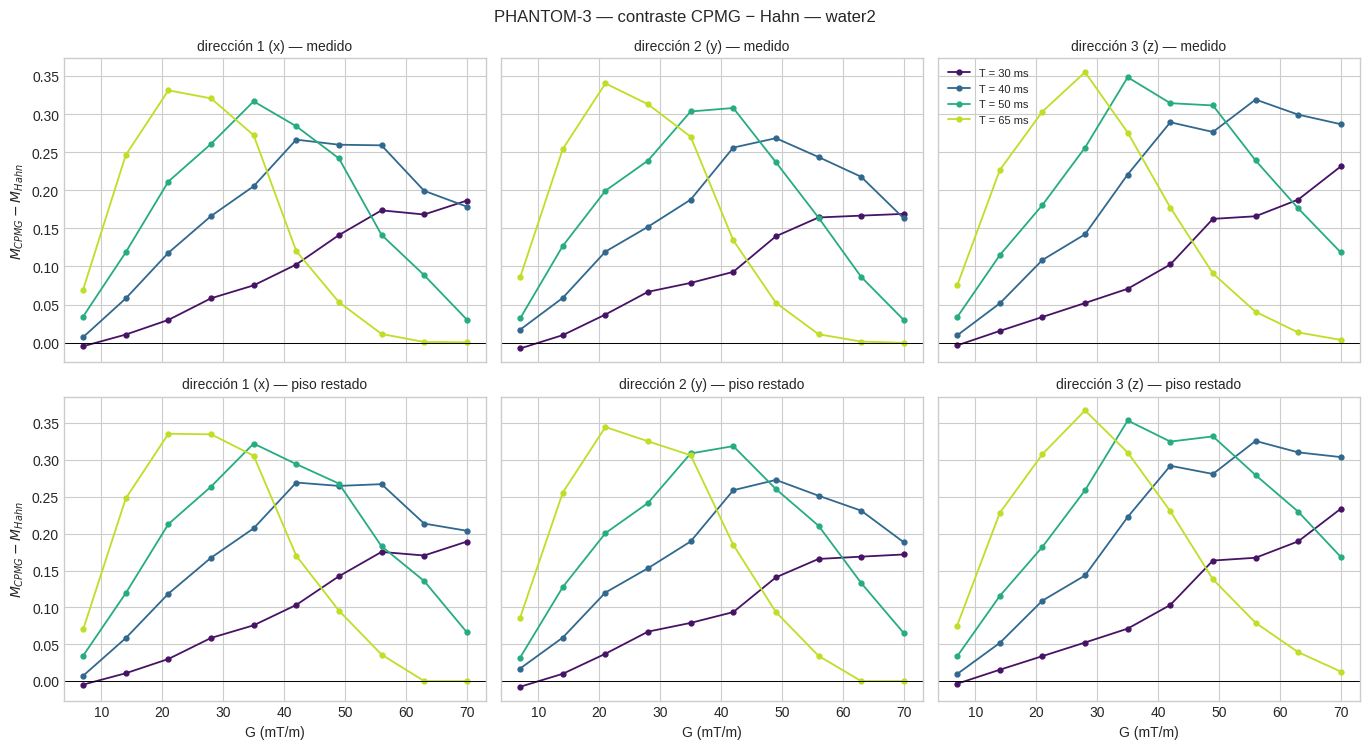

In [5]:
keys = ['roi', 'td_ms', 'direction', 'b_step']
columns = ['G_plot', 'value_norm', 'value_norm_corr']
cpmg = data.loc[data['type'].eq('CPMG'), keys + columns]
hahn = data.loc[data['type'].eq('HAHN'), keys + columns]
contrast = cpmg.merge(hahn, on=keys, how='inner', suffixes=('_cpmg', '_hahn'), validate='one_to_one')
if not np.allclose(contrast['G_plot_cpmg'], contrast['G_plot_hahn'], atol=0.05):
    raise ValueError('CPMG y Hahn no tienen el mismo G en todos los puntos emparejados.')
contrast['G_plot'] = contrast['G_plot_cpmg']
for column in CORRECTIONS.values():
    contrast[column] = contrast[f'{column}_cpmg'] - contrast[f'{column}_hahn']
contrast.to_csv(TABLE_DIR / 'contrasts.csv', index=False)

for roi in rois:
    fig, axes = plt.subplots(len(CORRECTIONS), len(directions), figsize=(4.6 * len(directions), 3.8 * len(CORRECTIONS)),
                             sharex=True, sharey='row', squeeze=False)
    for row, (correction, column) in enumerate(CORRECTIONS.items()):
        for col, direction in enumerate(directions):
            ax = axes[row, col]
            for td_ms in times:
                curve = contrast.loc[contrast['roi'].eq(roi) & contrast['td_ms'].eq(td_ms) & contrast['direction'].eq(direction)]
                plot_g_curve(ax, curve, column, time_colors[td_ms], 'o', f'T = {td_ms:g} ms')
            ax.axhline(0, color='k', lw=0.7)
            ax.set_title(f'{direction_names.get(direction, direction)} — {correction}', fontsize=10)
            if row == len(CORRECTIONS) - 1:
                ax.set_xlabel('G (mT/m)')
            if col == 0:
                ax.set_ylabel('$M_{CPMG} - M_{Hahn}$')
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f'{SUB} — contraste CPMG − Hahn — {roi}', fontsize=12)
    fig.tight_layout()
    save_figure(fig, CONTRAST_DIR, f'contrast_{roi}')
    plt.show()

## Fibras contra agua: una figura por dirección

Filas: medido y con el piso restado. Columnas: tiempos $T$. Una curva por ROI.

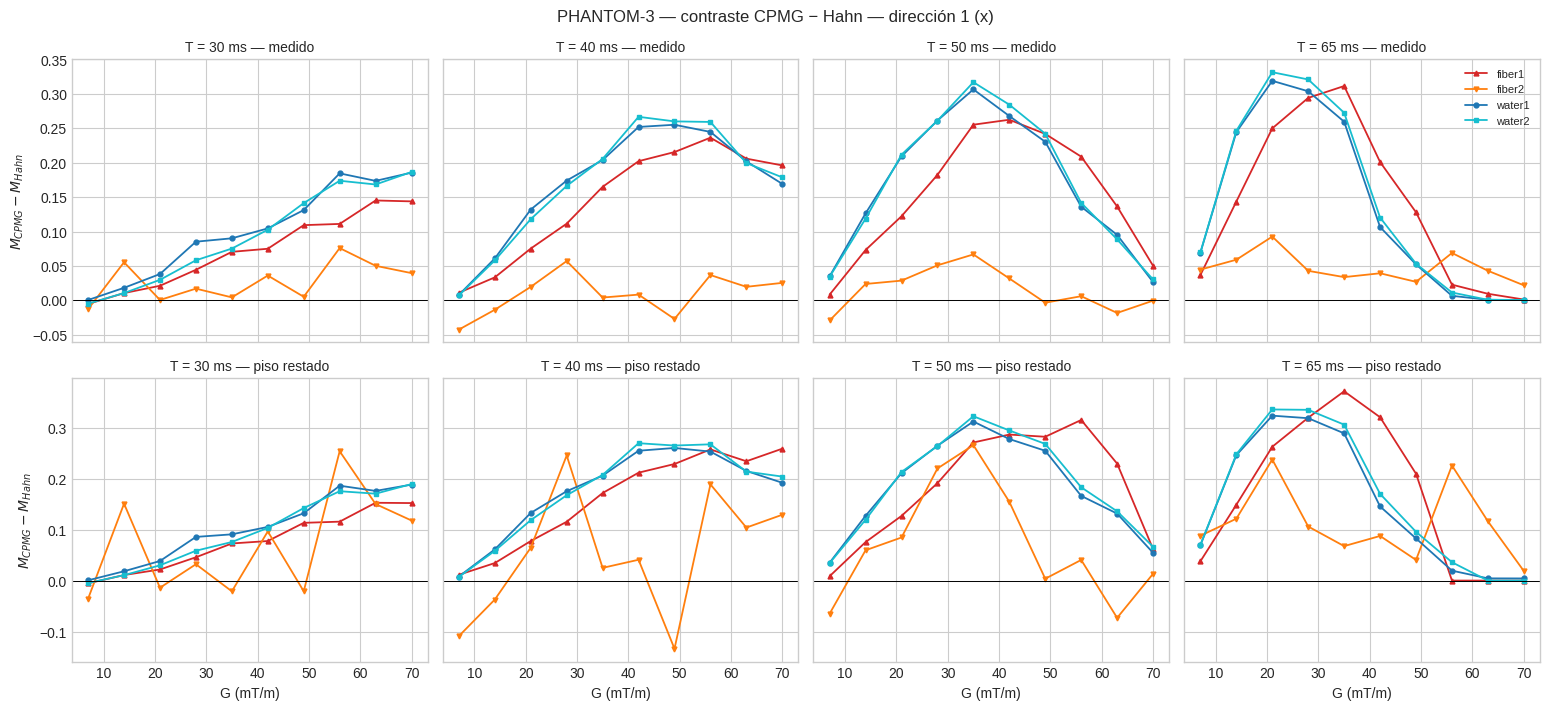

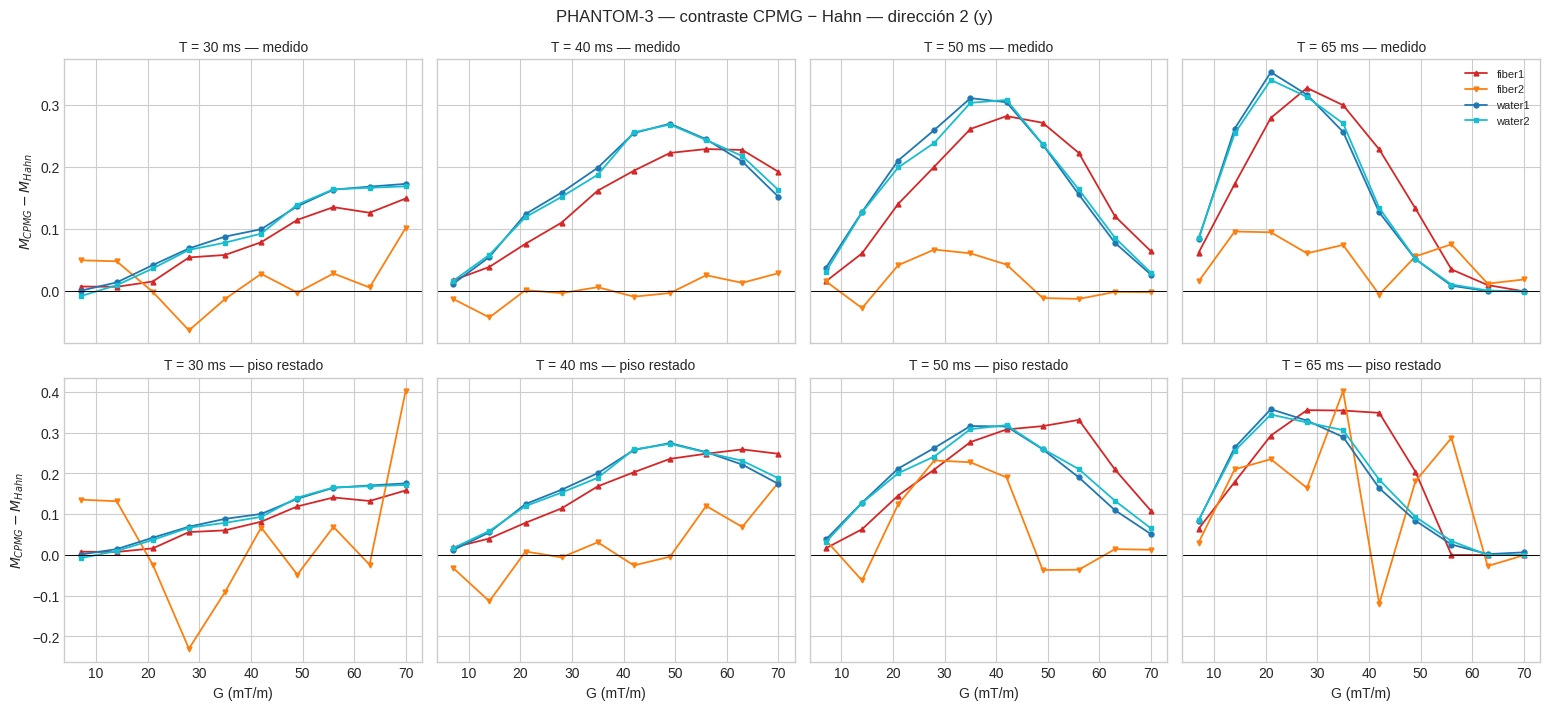

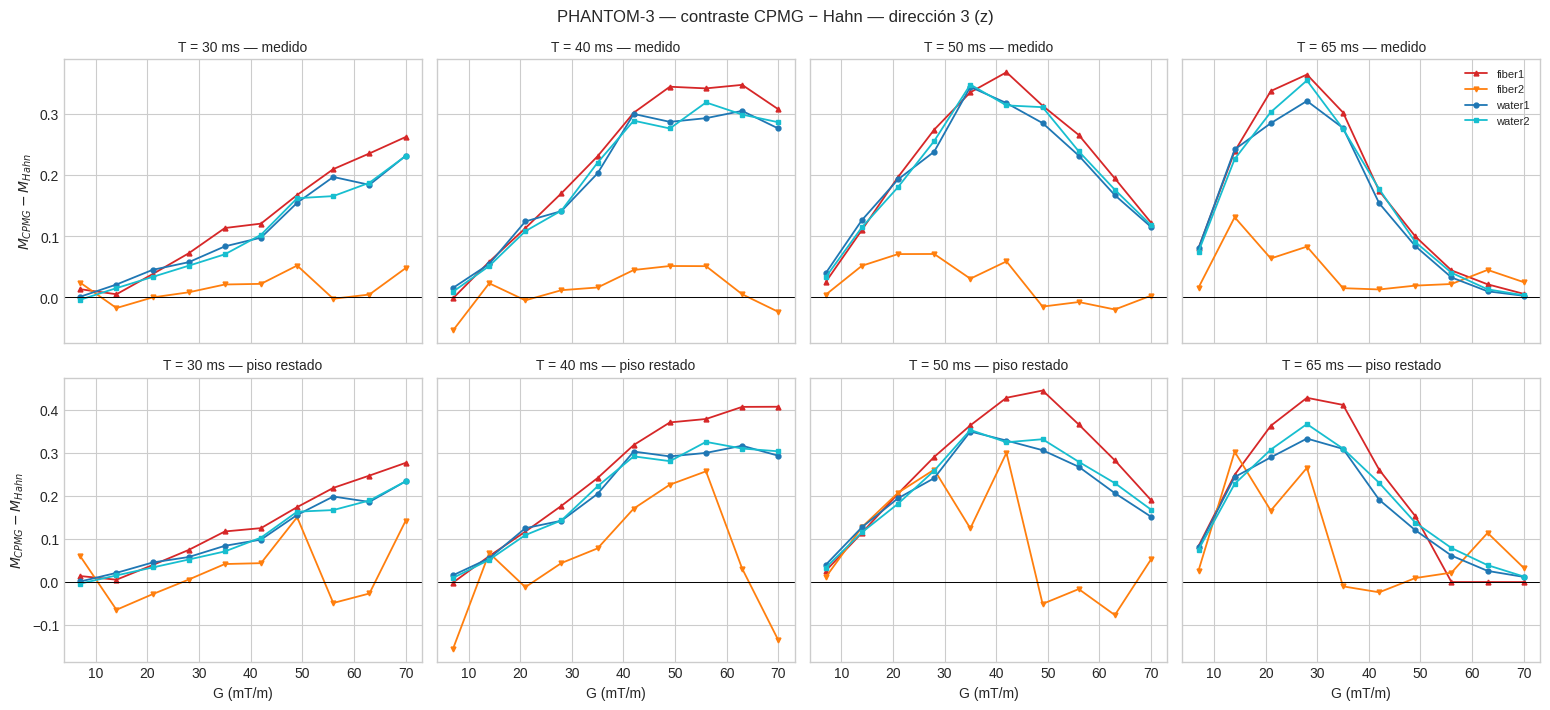

In [6]:
for direction in directions:
    fig, axes = plt.subplots(len(CORRECTIONS), len(times), figsize=(3.9 * len(times), 3.6 * len(CORRECTIONS)),
                             sharex=True, sharey='row', squeeze=False)
    for row, (correction, column) in enumerate(CORRECTIONS.items()):
        for col, td_ms in enumerate(times):
            ax = axes[row, col]
            for roi in rois:
                curve = contrast.loc[contrast['roi'].eq(roi) & contrast['td_ms'].eq(td_ms) & contrast['direction'].eq(direction)]
                color, marker = roi_style(roi)
                plot_g_curve(ax, curve, column, color, marker, roi)
            ax.axhline(0, color='k', lw=0.7)
            ax.set_title(f'T = {td_ms:g} ms — {correction}', fontsize=10)
            if row == len(CORRECTIONS) - 1:
                ax.set_xlabel('G (mT/m)')
            if col == 0:
                ax.set_ylabel('$M_{CPMG} - M_{Hahn}$')
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f'{SUB} — contraste CPMG − Hahn — {direction_names.get(direction, direction)}', fontsize=12)
    fig.tight_layout()
    save_figure(fig, CONTRAST_DIR, f'contrast_rois_direction-{direction}')
    plt.show()

## Pico del contraste medido

Máximo de $\Delta M$ sobre los $G$ medidos y el $G$ donde ocurre, por ROI, $T$ y dirección (grilla de 7 mT/m: el pico real puede estar entre
puntos; si el máximo está en 70 mT/m el pico queda fuera del rango).

In [7]:
peak_rows = []
for (roi, td_ms, direction), curve in contrast.groupby(['roi', 'td_ms', 'direction'], sort=True):
    row = {'roi': roi, 'td_ms': td_ms, 'direction': direction}
    for correction, column in CORRECTIONS.items():
        best = curve.loc[curve[column].idxmax()]
        row[f'peak_{column}'] = float(best[column])
        row[f'G_peak_{column}'] = float(best['G_plot'])
    peak_rows.append(row)
peaks = pd.DataFrame(peak_rows)
peaks.to_csv(TABLE_DIR / 'contrast_peaks.csv', index=False)
display(peaks.pivot_table(index=['roi', 'td_ms'], columns='direction', values=['peak_value_norm', 'peak_value_norm_corr']).round(3))
print('Figuras y tablas guardadas en:', OUTPUT_ROOT)

peak_value_norm               peak_value_norm_corr              
direction                  1      2      3                    1      2      3
roi    td_ms                                                                 
fiber1 30.0            0.145  0.150  0.263                0.153  0.158  0.277
       40.0            0.236  0.229  0.348                0.259  0.259  0.407
       50.0            0.262  0.282  0.369                0.315  0.332  0.445
       65.0            0.311  0.328  0.365                0.371  0.355  0.428
fiber2 30.0            0.076  0.102  0.052                0.254  0.404  0.151
       40.0            0.057  0.029  0.052                0.245  0.178  0.257
       50.0            0.067  0.067  0.071                0.266  0.232  0.300
       65.0            0.093  0.096  0.131                0.237  0.403  0.303
water1 30.0            0.186  0.173  0.232                0.188  0.176  0.234
       40.0            0.255  0.270  0.305                0.260  0.275  0.317
       50.0            0.306  0.311  0.345                0.312  0.317  0.350
       65.0            0.319  0.353  0.322                0.323  0.358  0.333
water2 30.0            0.187  0.169  0.232                0.189  0.172  0.234
       40.0            0.267  0.269  0.319                0.269  0.273  0.326
       50.0            0.317  0.308  0.349                0.322  0.319  0.354
       65.0            0.331  0.341  0.355                0.336  0.345  0.367

Figuras y tablas guardadas en: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autog_plots/sub-PHANTOM-3/ses-20261026NOGSEV2001FOV220M128SL01R1G070AUTOG
